# PolyLingo AI
## Four-Language Neural Machine Translation System

**اللغات المدعومة:** العربية، English، Français، 中文.

في هذا المشروع أبني نظام ترجمة متعدد اللغات باستخدام **NLLB-200 distilled 600M** ثم أخصصه للغات الأربع باستخدام **LoRA Fine-Tuning** بدل تدريب Transformer من الصفر.

سأقارن بين:
1. النموذج pretrained قبل التدريب.
2. النموذج بعد LoRA Fine-Tuning.

وسأستخدم **BLEU** و **chrF++** على جميع اتجاهات الترجمة الـ12.

### قرارات منهجية مهمة
- OPUS-100 English-centric في التدريب الأساسي، لذلك أستخدمه للأزواج المرتبطة بالإنجليزية.
- أضيف 4-way aligned bridge corpus لتوفير أمثلة مباشرة بين العربية والفرنسية والصينية أيضًا.
- أقسم البيانات المصفوفة قبل توليد الاتجاهات حتى لا يظهر نفس المعنى في Train باتجاه وفي Test باتجاه آخر.
- لا أستخدم Test Set لاختيار الإعدادات.


In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\abdu7\anaconda3\envs\iotguard\python.exe
PyTorch: 2.14.1+cu126
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 1. تثبيت المكتبات

أستخدم مكتبات مستقرة ومناسبة للترجمة العصبية وPEFT والتقييم العلمي.


In [2]:
import sys, subprocess, importlib.util

requirements = [
    "transformers>=4.48,<6",
    "datasets>=3.0",
    "peft>=0.14",
    "accelerate>=1.0",
    "sentencepiece>=0.2",
    "sacrebleu>=2.4",
    "gradio>=5.0",
    "pandas>=2.0",
]

missing=[]
for package in requirements:
    module=package.split('>=')[0].split('<')[0]
    if importlib.util.find_spec(module) is None:
        missing.append(package)

if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])

print('Dependencies are ready.')


Dependencies are ready.


## 2. إعداد المشروع والـGPU


In [3]:
from pathlib import Path
import os, json, time

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name.lower()=='notebooks':
    PROJECT_ROOT=PROJECT_ROOT.parent

DATA_DIR=PROJECT_ROOT/'data'
CACHE_DIR=DATA_DIR/'hf_cache'
PROCESSED_DIR=DATA_DIR/'processed'
RESULTS_DIR=PROJECT_ROOT/'results'
MODELS_DIR=PROJECT_ROOT/'models'
ADAPTER_DIR=MODELS_DIR/'polyligo_nllb_lora'

for p in [DATA_DIR,CACHE_DIR,PROCESSED_DIR,RESULTS_DIR,MODELS_DIR,ADAPTER_DIR]:
    p.mkdir(parents=True,exist_ok=True)

os.environ['HF_HOME']=str(CACHE_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset

from helper import (
    LANGUAGES, ALL_DIRECTIONS, ProjectConfig, set_seed, get_device,
    print_environment, normalize_text, clean_parallel_dataframe,
    split_aligned_by_anchor, aligned_holdout_english_anchors,
    explode_aligned_rows, opus_pair_to_dataframe, balanced_direction_sample,
    stratified_eval_sample, direction_table, tokenize_multilingual_dataframe,
    build_lora_nllb, print_trainable_parameters, TranslationTrainer,
    NLLBTranslator, evaluate_translation_dataframe,
    load_adapter_for_inference, cleanup_cuda,
)

CONFIG=ProjectConfig()
set_seed(CONFIG.seed)
print_environment()
print('Project root:',PROJECT_ROOT)


C:\Users\abdu7\anaconda3\envs\iotguard\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.14.1+cu126
Device  : cuda
CUDA    : 12.6
GPU     : NVIDIA GeForce RTX 4070 Laptop GPU
VRAM GB : 8.0
Project root: D:\PolyLingo_AI


### إعدادات التدريب

الإعدادات مصممة لجهاز RTX 4070 Laptop بذاكرة 8GB:
- LoRA بدل Full Fine-Tuning.
- Gradient Checkpointing لتقليل الذاكرة.
- FP16 على CUDA.
- Batch size صغير مع Gradient Accumulation.
- Label Smoothing = 0.1.
- Warmup + Cosine schedule.
- Gradient clipping.
- Beam Search = 4 أثناء التقييم.


In [4]:
display(pd.DataFrame(CONFIG.to_dict().items(),columns=["Parameter","Value"]))


,Parameter,Value
0,seed,42
1,model_name,facebook/nllb-200-distilled-600M
2,train_per_direction,5000
3,eval_per_direction,150
4,anchor_examples_per_pair,12000
5,max_source_length,128
6,max_target_length,128
7,lora_r,16
8,lora_alpha,32
9,lora_dropout,0.05


# Part A — Data Engineering


## 3. تحميل 4-way aligned bridge corpus

أستخدم فقط الإنجليزية والفرنسية والعربية والصينية، وأنظف النصوص قبل أي تدريب.


In [5]:
bridge_raw=load_dataset(
    'nirmalendu01/opus100-en-fr-de-ar-zh',
    split='train',
    cache_dir=str(CACHE_DIR),
)

bridge_df=bridge_raw.to_pandas()[['en','fr','ar','zh']].copy()
for col in ['en','fr','ar','zh']:
    bridge_df[col]=bridge_df[col].map(normalize_text)

bridge_df=bridge_df.dropna().drop_duplicates(subset=['en'])
bridge_df=bridge_df[
    bridge_df[['en','fr','ar','zh']].apply(
        lambda row: all(len(str(x))>=4 for x in row),axis=1
    )
].reset_index(drop=True)

print('Aligned rows:',len(bridge_df))
display(bridge_df.head())


Aligned rows: 7495


,en,fr,ar,zh
0,"""Us""?","""Nous"" ?","منا""؟""","- ""我们""?"
1,"""We""?",""" On "" ?",نحن - !,"""我们"""
2,(CHUCKLES),(GLOUSSEMENTS),(ضحكات),(莞尔)
3,(GASPS),(Halètements),(صيحات),(喘气)
4,(GROANING),Enlevons ça.,(يئن),(连天)


## 4. Split قبل توليد الاتجاهات

أقسم المعاني المصفوفة أولًا. بهذه الطريقة لا يمكن أن تدخل الجملة نفسها إلى Train كـArabic→English ثم تظهر في Test كـEnglish→Chinese.


In [6]:
bridge_train_aligned,bridge_val_aligned,bridge_test_aligned=split_aligned_by_anchor(
    bridge_df,seed=CONFIG.seed,train_ratio=.80,val_ratio=.10
)
print('Aligned train:',len(bridge_train_aligned))
print('Aligned val  :',len(bridge_val_aligned))
print('Aligned test :',len(bridge_test_aligned))


Aligned train: 5996
Aligned val  : 749
Aligned test : 750


## 5. توليد الاتجاهات الـ12


In [7]:
bridge_train=explode_aligned_rows(bridge_train_aligned)
bridge_val=explode_aligned_rows(bridge_val_aligned)
bridge_test=explode_aligned_rows(bridge_test_aligned)
print('Train directed:',len(bridge_train))
print('Val directed  :',len(bridge_val))
print('Test directed :',len(bridge_test))
display(direction_table(bridge_train))


Train directed: 67366
Val directed  : 8450
Test directed : 8372


,direction,examples
0,ar->en,5937
1,ar->fr,5879
2,ar->zh,5463
3,en->ar,5937
4,en->fr,5756
5,en->zh,5519
6,fr->ar,5879
7,fr->en,5756
8,fr->zh,5129
9,zh->ar,5463


## 6. إضافة OPUS-100 للأزواج المرتبطة بالإنجليزية

أستخدم:
- Arabic ↔ English
- English ↔ French
- English ↔ Chinese

وأمنع English anchors الموجودة في Validation/Test من الدخول إلى Train.


In [8]:
holdout_english=aligned_holdout_english_anchors(bridge_val_aligned,bridge_test_aligned)
anchor_specs=[('ar-en','ar','en'),('en-fr','en','fr'),('en-zh','en','zh')]
anchor_parts=[]

for config_name,a,b in anchor_specs:
    print('Loading',config_name)
    ds=load_dataset(
        'Helsinki-NLP/opus-100',
        config_name,
        split=f'train[:{CONFIG.anchor_examples_per_pair}]',
        cache_dir=str(CACHE_DIR),
    )
    part=opus_pair_to_dataframe(
        ds,a,b,holdout_english=holdout_english,bidirectional=True
    )
    anchor_parts.append(part)
    print(config_name,'clean directed rows:',len(part))

anchor_train=pd.concat(anchor_parts,ignore_index=True)
display(direction_table(anchor_train))


Loading ar-en
ar-en clean directed rows: 22694
Loading en-fr
en-fr clean directed rows: 22710
Loading en-zh
en-zh clean directed rows: 18972


,direction,examples
0,ar->en,11347
1,en->ar,11347
2,en->fr,11355
3,en->zh,9486
4,fr->en,11355
5,zh->en,9486


## 7. الدمج والموازنة

لا أسمح للأزواج الإنجليزية الأكبر أن تهيمن على التدريب. أضع حدًا لكل اتجاه، ثم أستخدم Temperature-smoothed sampling داخل DataLoader.


In [9]:
# ------------------------------------------------------------
# Build holdout pair keys first
# ------------------------------------------------------------

def make_pair_key(df):
    return (
        df["source"].str.casefold()
        + " || "
        + df["target"].str.casefold()
        + " || "
        + df["src_lang"]
        + " || "
        + df["tgt_lang"]
    )


# Validation and Test are fixed first
val_df = stratified_eval_sample(
    bridge_val,
    per_direction=CONFIG.eval_per_direction,
    seed=CONFIG.seed,
)

test_df = stratified_eval_sample(
    bridge_test,
    per_direction=CONFIG.eval_per_direction,
    seed=CONFIG.seed + 1,
)

# Build exact holdout keys
holdout_keys = set(make_pair_key(val_df)) | set(make_pair_key(test_df))


# ------------------------------------------------------------
# Combine training sources
# ------------------------------------------------------------

combined_train = pd.concat(
    [bridge_train, anchor_train],
    ignore_index=True,
)

combined_train = clean_parallel_dataframe(combined_train)

print("Combined train before leakage filtering:", len(combined_train))


# ------------------------------------------------------------
# Remove every exact pair appearing in validation or test
# ------------------------------------------------------------

combined_train["_pair_key"] = make_pair_key(combined_train)

combined_train = combined_train[
    ~combined_train["_pair_key"].isin(holdout_keys)
].copy()

combined_train = (
    combined_train
    .drop(columns="_pair_key")
    .reset_index(drop=True)
)

print("Combined train after leakage filtering :", len(combined_train))


# ------------------------------------------------------------
# Balance AFTER leakage removal
# ------------------------------------------------------------

train_df = balanced_direction_sample(
    combined_train,
    per_direction=CONFIG.train_per_direction,
    seed=CONFIG.seed,
)

print("\nFinal train:", len(train_df))
print("Final val  :", len(val_df))
print("Final test :", len(test_df))

print("\nTRAIN DISTRIBUTION")
display(direction_table(train_df))

print("\nVAL DISTRIBUTION")
display(direction_table(val_df))

Combined train before leakage filtering: 129106
Combined train after leakage filtering : 129098

Final train: 60000
Final val  : 1800
Final test : 1800

TRAIN DISTRIBUTION


,direction,examples
0,ar->en,5000
1,ar->fr,5000
2,ar->zh,5000
3,en->ar,5000
4,en->fr,5000
5,en->zh,5000
6,fr->ar,5000
7,fr->en,5000
8,fr->zh,5000
9,zh->ar,5000



VAL DISTRIBUTION


,direction,examples
0,ar->en,150
1,ar->fr,150
2,ar->zh,150
3,en->ar,150
4,en->fr,150
5,en->zh,150
6,fr->ar,150
7,fr->en,150
8,fr->zh,150
9,zh->ar,150


## 8. فحص Data Leakage


In [10]:
def pair_keys(df):
    return set(
        zip(
            df["source"].str.casefold(),
            df["target"].str.casefold(),
            df["src_lang"],
            df["tgt_lang"],
        )
    )


tr = pair_keys(train_df)
va = pair_keys(val_df)
te = pair_keys(test_df)

print("Train ∩ Val :", len(tr & va))
print("Train ∩ Test:", len(tr & te))
print("Val ∩ Test  :", len(va & te))

assert len(tr & va) == 0
assert len(tr & te) == 0
assert len(va & te) == 0

print("\nNo exact translation-pair leakage detected.")


Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0

No exact translation-pair leakage detected.


## 9. حفظ البيانات المعالجة


In [11]:
train_df.to_parquet(PROCESSED_DIR/'translation_train.parquet',index=False)
val_df.to_parquet(PROCESSED_DIR/'translation_val.parquet',index=False)
test_df.to_parquet(PROCESSED_DIR/'translation_test.parquet',index=False)
print('Saved processed datasets.')


Saved processed datasets.


# Part B — Pretrained Baseline


## 10. تحميل NLLB + LoRA

قبل التدريب أقيس النموذج pretrained كما هو. LoRA يبدأ بدون تغيير فعال في مخرجات النموذج الأساسي، لذلك هذه هي نقطة المقارنة الحقيقية.


In [12]:
tokenizer,lora_model=build_lora_nllb(CONFIG)
parameter_info=print_trainable_parameters(lora_model)


Loading weights: 100%|██████████| 512/512 [00:03<00:00, 156.74it/s]


Trainable parameters : 4,718,592
Total parameters     : 619,792,384
Trainable %          : 0.7613%


## 11. Baseline BLEU / chrF++


In [13]:
baseline_translator=NLLBTranslator(lora_model,tokenizer,device=get_device())
baseline_metrics,baseline_predictions=evaluate_translation_dataframe(
    baseline_translator,
    val_df,
    num_beams=CONFIG.num_beams,
    max_new_tokens=CONFIG.generation_max_new_tokens,
    batch_size=CONFIG.eval_batch_size,
)
display(baseline_metrics.round(3))
baseline_metrics.to_csv(RESULTS_DIR/'baseline_validation_metrics.csv',index=False)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,direction,examples,BLEU,chrF++
0,ar->en,150,38.553,62.522
1,ar->fr,150,15.046,36.304
2,ar->zh,150,18.073,15.223
3,en->ar,150,16.237,38.355
4,en->fr,150,22.000,43.159
5,en->zh,150,22.205,17.687
6,fr->ar,150,7.510,25.649
7,fr->en,150,32.075,53.305
8,fr->zh,150,13.548,12.849
9,zh->ar,150,4.848,24.289


# Part C — Tokenization


## 12. Tokenization حسب اتجاه اللغة

NLLB يحتاج كود مصدر وهدف صحيح لكل اتجاه، لذلك أعمل tokenization لكل direction منفصلًا ثم أدمج النتائج.


In [14]:
train_tokenized=tokenize_multilingual_dataframe(
    train_df,tokenizer,CONFIG.max_source_length,CONFIG.max_target_length
)
val_tokenized=tokenize_multilingual_dataframe(
    val_df,tokenizer,CONFIG.max_source_length,CONFIG.max_target_length
)
print(train_tokenized)
print(val_tokenized)


Tokenizing zh->fr: 100%|██████████| 150/150 [00:00<00:00, 18154.02 examples/s]

Dataset({
    features: ['src_lang', 'tgt_lang', 'pair', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 60000
})
Dataset({
    features: ['src_lang', 'tgt_lang', 'pair', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 1800
})


# Part D — LoRA Fine-Tuning


## 13. التدريب

أستخدم AdamW + Label Smoothing + Warmup + Cosine decay + Gradient clipping + Mixed precision + Gradient checkpointing.

أختار أفضل Adapter حسب Validation Loss، ثم أتحقق من BLEU/chrF++ بعد التدريب.


In [16]:
import importlib
import helper

helper = importlib.reload(helper)

print(helper.__file__)

D:\PolyLingo_AI\helper.py


In [17]:
trainer = helper.TranslationTrainer(
    lora_model,
    tokenizer,
    CONFIG,
    ADAPTER_DIR,
    device=helper.get_device()
)

train_loader, val_loader = trainer._build_loaders(
    train_tokenized,
    val_tokenized
)

batch = next(iter(train_loader))

print("Batch keys:")
print(batch.keys())

for key, value in batch.items():
    print(
        key,
        type(value),
        value.shape if hasattr(value, "shape") else None
    )

Training columns passed to model: ['input_ids', 'attention_mask', 'labels']
Validation columns passed to model: ['input_ids', 'attention_mask', 'labels']
Batch keys:
KeysView({'input_ids': tensor([[256047,    117, 248116, 248070,   2294,  22802,   5563, 248075,      2,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1],
        [256011,   4590, 171535,      2,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1],
        [256057,     89, 184065, 248075,      2,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1],
        [256011,  10588,   6277, 120104,  77671,   3424, 131382,   7325, 248142,
         248679,   2147,     89,   9446,  15776,  11506, 155029,   7970,    471,
             89,      2]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 

In [18]:
history = trainer.fit(
    train_tokenized,
    val_tokenized
)

Training columns passed to model: ['input_ids', 'attention_mask', 'labels']
Validation columns passed to model: ['input_ids', 'attention_mask', 'labels']
Device               : cuda
Train batches/epoch  : 15000
Train batch size     : 4
Gradient accumulation: 4
Effective batch size : 16
Optimizer steps/epoch: 3750
Epoch 1/2 | batch 250/15000 | train_loss=3.9205
Epoch 1/2 | batch 500/15000 | train_loss=3.8664
Epoch 1/2 | batch 750/15000 | train_loss=3.7634
Epoch 1/2 | batch 1000/15000 | train_loss=3.6758
Epoch 1/2 | batch 1250/15000 | train_loss=3.6060
Epoch 1/2 | batch 1500/15000 | train_loss=3.5566
Epoch 1/2 | batch 1750/15000 | train_loss=3.5243
Epoch 1/2 | batch 2000/15000 | train_loss=3.4875
Epoch 1/2 | batch 2250/15000 | train_loss=3.4623
Epoch 1/2 | batch 2500/15000 | train_loss=3.4443
Epoch 1/2 | batch 2750/15000 | train_loss=3.4260
Epoch 1/2 | batch 3000/15000 | train_loss=3.4062
Epoch 1/2 | batch 3250/15000 | train_loss=3.3911
Epoch 1/2 | batch 3500/15000 | train_loss=3.3768
Ep

## 14. منحنيات Loss


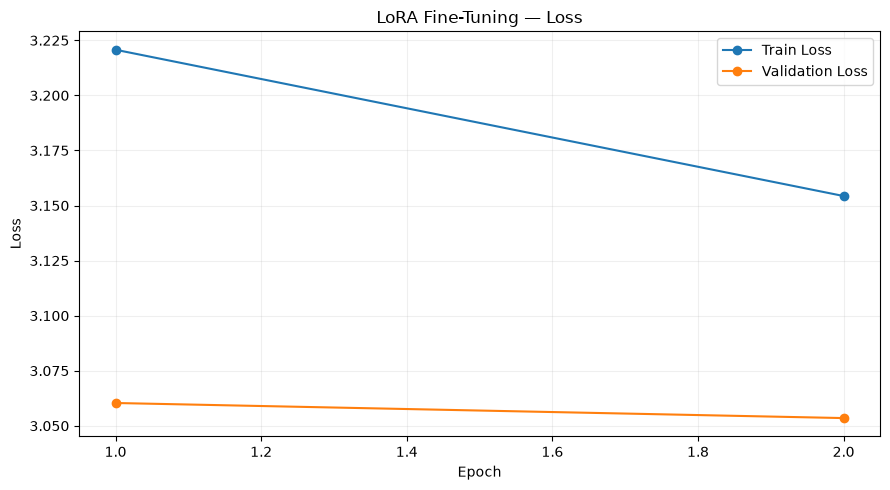

Best epoch: 2
Best validation loss: 3.053499825530582


In [19]:
epochs=range(1,len(history['train_loss'])+1)
plt.figure(figsize=(9,5))
plt.plot(epochs,history['train_loss'],marker='o',label='Train Loss')
plt.plot(epochs,history['val_loss'],marker='o',label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('LoRA Fine-Tuning — Loss')
plt.legend(); plt.grid(alpha=.2); plt.tight_layout()
plt.savefig(RESULTS_DIR/'training_validation_loss.png',dpi=180,bbox_inches='tight')
plt.show()
print('Best epoch:',trainer.best_epoch)
print('Best validation loss:',trainer.best_val_loss)


# Part E — Post Fine-Tuning Evaluation


## 15. تحميل أفضل Adapter


In [20]:
cleanup_cuda()
best_adapter=ADAPTER_DIR/'best_adapter'
best_tokenizer,best_model=load_adapter_for_inference(
    CONFIG.model_name,best_adapter,device=get_device()
)
fine_translator=NLLBTranslator(best_model,best_tokenizer,device=get_device())
print('Best adapter loaded.')


Loading weights: 100%|██████████| 512/512 [00:01<00:00, 446.17it/s]


Best adapter loaded.


## 16. Validation بعد Fine-Tuning


In [21]:
fine_val_metrics,fine_val_predictions=evaluate_translation_dataframe(
    fine_translator,
    val_df,
    num_beams=CONFIG.num_beams,
    max_new_tokens=CONFIG.generation_max_new_tokens,
    batch_size=CONFIG.eval_batch_size,
)
display(fine_val_metrics.round(3))
fine_val_metrics.to_csv(RESULTS_DIR/'finetuned_validation_metrics.csv',index=False)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,direction,examples,BLEU,chrF++
0,ar->en,150,54.620,66.373
1,ar->fr,150,26.109,41.233
2,ar->zh,150,18.294,14.954
3,en->ar,150,19.924,39.362
4,en->fr,150,32.272,49.066
5,en->zh,150,21.993,17.584
6,fr->ar,150,9.803,27.946
7,fr->en,150,50.358,60.244
8,fr->zh,150,15.450,13.664
9,zh->ar,150,7.958,25.351


## 17. Before vs After


In [22]:
comparison=baseline_metrics.merge(
    fine_val_metrics,on='direction',suffixes=('_baseline','_finetuned')
)
comparison['BLEU_gain']=comparison['BLEU_finetuned']-comparison['BLEU_baseline']
comparison['chrF++_gain']=comparison['chrF++_finetuned']-comparison['chrF++_baseline']
display(comparison[[
    'direction','BLEU_baseline','BLEU_finetuned','BLEU_gain',
    'chrF++_baseline','chrF++_finetuned','chrF++_gain'
]].round(3))
comparison.to_csv(RESULTS_DIR/'before_after_comparison.csv',index=False)


,direction,BLEU_baseline,BLEU_finetuned,BLEU_gain,chrF++_baseline,chrF++_finetuned,chrF++_gain
0,ar->en,38.553,54.620,16.066,62.522,66.373,3.851
1,ar->fr,15.046,26.109,11.063,36.304,41.233,4.929
2,ar->zh,18.073,18.294,0.222,15.223,14.954,-0.269
3,en->ar,16.237,19.924,3.688,38.355,39.362,1.007
4,en->fr,22.000,32.272,10.272,43.159,49.066,5.907
5,en->zh,22.205,21.993,-0.212,17.687,17.584,-0.103
6,fr->ar,7.510,9.803,2.293,25.649,27.946,2.297
7,fr->en,32.075,50.358,18.283,53.305,60.244,6.939
8,fr->zh,13.548,15.450,1.902,12.849,13.664,0.815
9,zh->ar,4.848,7.958,3.111,24.289,25.351,1.062


### تفسير النتيجة

أفحص كل اتجاه على حدة، خصوصًا Arabic↔Chinese وArabic↔French وFrench↔Chinese. إذا تحسنت الاتجاهات المرتبطة بالإنجليزية بينما انخفضت الاتجاهات الأخرى، أذكر ذلك كـmultilingual interference بدل الاكتفاء بالمتوسط.


# Part F — Final Test


## 18. فتح Test Set مرة واحدة


In [23]:
test_metrics,test_predictions=evaluate_translation_dataframe(
    fine_translator,
    test_df,
    num_beams=CONFIG.num_beams,
    max_new_tokens=CONFIG.generation_max_new_tokens,
    batch_size=CONFIG.eval_batch_size,
)
display(test_metrics.round(3))
test_metrics.to_csv(RESULTS_DIR/'final_test_metrics.csv',index=False)
test_predictions.to_parquet(RESULTS_DIR/'final_test_predictions.parquet',index=False)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,direction,examples,BLEU,chrF++
0,ar->en,150,47.917,64.255
1,ar->fr,150,25.910,41.752
2,ar->zh,150,18.968,15.320
3,en->ar,150,19.591,38.089
4,en->fr,150,33.355,49.414
5,en->zh,150,24.679,19.814
6,fr->ar,150,13.373,31.692
7,fr->en,150,45.558,57.526
8,fr->zh,150,17.742,14.735
9,zh->ar,150,8.273,26.755


## 19. أمثلة نوعية


In [24]:
sample_rows=[]
for direction in ALL_DIRECTIONS:
    part=test_predictions[test_predictions['pair']==direction]
    if not part.empty:
        sample_rows.append(part.sample(n=min(2,len(part)),random_state=CONFIG.seed))
samples=pd.concat(sample_rows,ignore_index=True)
display(samples[['pair','source','target','prediction']])


,pair,source,target,prediction
0,ar->en,مالذي يتحدث عنه؟,What's he talking about?,What's he talking about?
1,ar->en,سامحيني أرجوك,Please forgive me.,Please forgive me.
2,ar->fr,هل يوجد أحد هنا ؟,Il y a quelqu'un ?,Quelqu'un ici ?
3,ar->fr,أمستريح؟,Vous etes bien installee ? Bon.,Vous vous reposez ?
4,ar->zh,انظري هذا؟,看看这个?,看看这?
5,ar->zh,ولقد رحلتْ.,她走了。,她走了
6,en->ar,You hear me?,هل تسمعيني؟,هل تسمعني؟
7,en->ar,- Easy.,- مهلاً -,-بسهولة
8,en->fr,Get your hands off me!,TOUCHE-MOI PAS !,Enlevez-moi vos mains !
9,en->fr,Endorses the conclusions and recommendations c...,Fait siennes les conclusions et recommandation...,Soutient les conclusions et recommandations co...


# Part G — Web Demo


## 20. واجهة ترجمة محلية

الواجهة تستخدم النموذج الذي دربته محليًا، ولا تستدعي API ترجمة خارجي.


In [27]:
import gradio as gr

DISPLAY_TO_CODE={'العربية':'ar','English':'en','Français':'fr','中文':'zh'}

def web_translate(text,source_language,target_language):
    text=(text or '').strip()
    if not text: return ''
    src=DISPLAY_TO_CODE[source_language]; tgt=DISPLAY_TO_CODE[target_language]
    if src==tgt: return text
    return fine_translator.translate(
        text,src,tgt,
        num_beams=CONFIG.num_beams,
        max_new_tokens=CONFIG.generation_max_new_tokens,
        batch_size=1,
    )

with gr.Blocks(title='PolyLingo AI') as demo:
    gr.Markdown('# PolyLingo AI### Arabic • English • French • Chinese Neural Translation')
    with gr.Row():
        src_dropdown=gr.Dropdown(list(DISPLAY_TO_CODE.keys()),value='العربية',label='Source Language')
        tgt_dropdown=gr.Dropdown(list(DISPLAY_TO_CODE.keys()),value='English',label='Target Language')
    input_text=gr.Textbox(lines=6,label='Input',placeholder='اكتب النص هنا...')
    translate_button=gr.Button('Translate')
    output_text=gr.Textbox(lines=6,label='Translation')
    translate_button.click(web_translate,[input_text,src_dropdown,tgt_dropdown],output_text)

demo.launch(share=False,inline=True,prevent_thread_lock=True)


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


# الخلاصة

هذا المشروع يطبق Transfer Learning في الترجمة العصبية بدل تدريب Transformer ضخم من الصفر.

**الأساليب الأساسية:**
- تنظيف وتصفية البيانات.
- إزالة التكرارات.
- Script validation للعربية والصينية.
- Split على مستوى الجملة المصفوفة قبل توليد الاتجاهات.
- منع leakage بين OPUS-100 والـheld-out bridge data.
- موازنة الاتجاهات.
- Temperature-smoothed multilingual sampling.
- LoRA.
- Label smoothing.
- AdamW.
- Warmup + cosine schedule.
- Gradient clipping.
- Mixed precision.
- Gradient checkpointing.
- Best-checkpoint selection.
- Beam search.
- BLEU + chrF++.

**حدود المشروع:** NLLB نموذج بحثي عام وليس مترجمًا معتمدًا للنصوص الطبية أو القانونية أو الوثائق الطويلة.
